In [16]:
import pandas as pd
import geopandas as gpd
import xarray as xr
import os
import numpy as np
from shapely.geometry import Polygon
from shapely.geometry import Point, box

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from pyproj import CRS, Proj, Transformer

from shapely import wkt

from scipy.interpolate import griddata

import warnings
warnings.filterwarnings("ignore")

In [2]:
regular_path = 'PM_AOD/5km_prediction_exp3/'
grid_path = 'PM_AOD/5km_grid_features/2004-01-01.nc'
study_area_path = 'Study area boundary shapefile/Counties_in_study_area.shp'

In [3]:
grid_ds = xr.open_dataset(grid_path)
proj_x = grid_ds['Projected X']
proj_y = grid_ds['Projected Y']

study_area = gpd.read_file(study_area_path).to_crs('ESRI:102003')
study_union = study_area.geometry.unary_union

In [4]:
all_files = sorted([f for f in os.listdir(regular_path) if f.endswith('.nc')])
all_files = [f for f in all_files if '2004-' <= f[:10] <= '2023-12-31']

In [5]:
daily_list = []
for fname in all_files:
    ds = xr.open_dataset(os.path.join(regular_path, fname))

    ds = ds.assign_coords({'Projected X': (('y','x'), proj_x.data),
                           'Projected Y': (('y','x'), proj_y.data)})
    ds = ds.rename({'prediction': 'pm25'}) if 'prediction' in ds else ds
    date_label = pd.to_datetime(fname[:10])
    ds = ds.expand_dims(time=[date_label])
    daily_list.append(ds[['pm25']])  

ds_daily = xr.concat(daily_list, dim='time').sortby('time')

In [9]:
def season_of_month(m):
    return 'DJF' if m in (12,1,2) else ('MAM' if m in (3,4,5) else ('JJA' if m in (6,7,8) else 'SON'))

# Annual mean

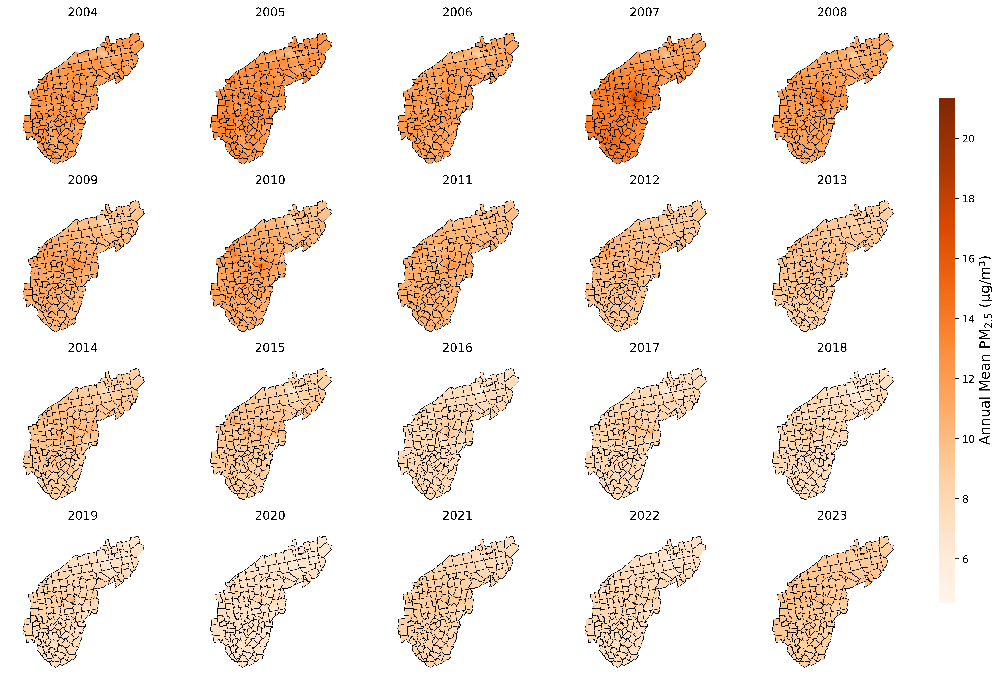

In [27]:
annual = ds_daily['pm25'].groupby('time.year').mean('time')  
ds = annual.to_dataset(name='prediction')                       

grid_ds = xr.open_dataset(grid_path)
ds['Projected X'] = grid_ds['Projected X']
ds['Projected Y'] = grid_ds['Projected Y']
ds = ds.assign_coords({
    'Projected X': (('y','x'), ds['Projected X'].data),
    'Projected Y': (('y','x'), ds['Projected Y'].data)
})

years = ds['year'].values
ds = ds.rename(year='time')

fig = plt.figure(figsize=(15, 10), dpi=600)
gs = gridspec.GridSpec(nrows=4, ncols=5, figure=fig, wspace=0.1, hspace=0.15)

vmin = float(ds['prediction'].min())
vmax = float(ds['prediction'].max())

for i, year in enumerate(years):
    row, col = divmod(i, 5)
    ax = fig.add_subplot(gs[row, col])

    im = ds['prediction'].sel(time=year).plot(
        ax=ax, x='Projected X', y='Projected Y',
        cmap='Oranges', vmin=vmin, vmax=vmax, add_colorbar=False
    )
    study_area.plot(ax=ax, facecolor='none', edgecolor='k', linewidth=0.5)
    ax.set_title(str(int(year)), fontsize=12, pad=2)
    ax.axis('off')

cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label(r'Annual Mean PM$_{2.5}$ (µg/m³)', fontsize=14)  
cbar.outline.set_visible(False)

plt.subplots_adjust(left=0.05, right=0.9, top=0.96, bottom=0.06)
plt.show()

# Time series

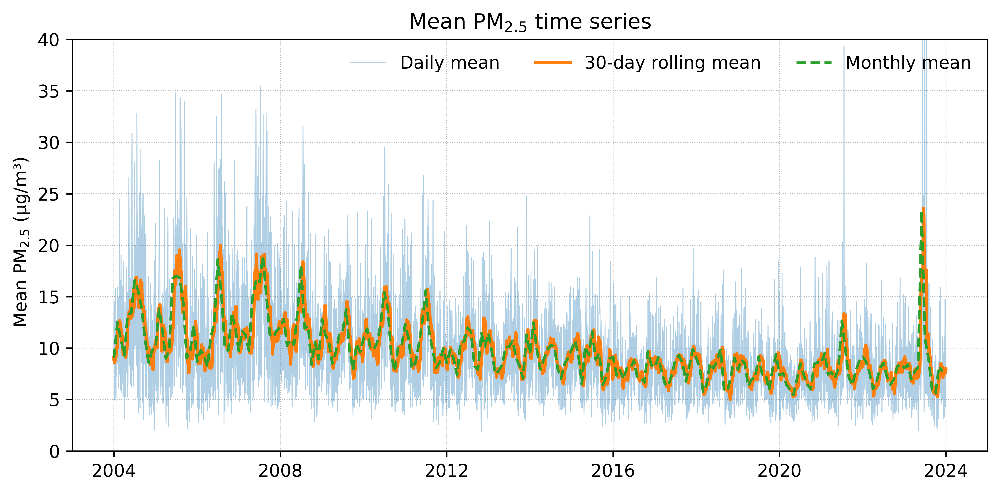

In [25]:
daily = ds_daily['pm25'].mean(('y','x'), skipna=True).to_series()
daily = daily.sort_index()

roll30 = daily.rolling(30, center=True, min_periods=15).mean()
monthly = daily.resample('MS').mean()

fig, ax = plt.subplots(figsize=(8, 4), dpi=600)
ax.plot(daily.index, daily.values, linewidth=0.5, alpha=0.35, label='Daily mean')
ax.plot(roll30.index, roll30.values, linewidth=1.8, label='30-day rolling mean')
ax.plot(monthly.index, monthly.values, linewidth=1.5, linestyle='--', label='Monthly mean')
ax.set_ylim(0,40)

ax.set_ylabel(' Mean PM$_{2.5}$ (µg/m³)')   
ax.set_title('Mean PM$_{2.5}$ time series')
ax.grid(True, linestyle=':', linewidth=0.5)
ax.legend(frameon=False, ncol=4, loc='upper right')
plt.tight_layout()
plt.show()

# Seasonal mean

In [10]:
seasonal_list = []
years = np.unique(ds_daily['time'].dt.year.values)
for y in years:
    sub = ds_daily.sel(time=str(y))
    seas = sub.groupby('time.season').mean('time')  # dims: season,y,x
    seas = seas.assign_coords(year=y)
    seasonal_list.append(seas)

seasonal_by_year = xr.concat(seasonal_list, dim='year').transpose('season','year','y','x')

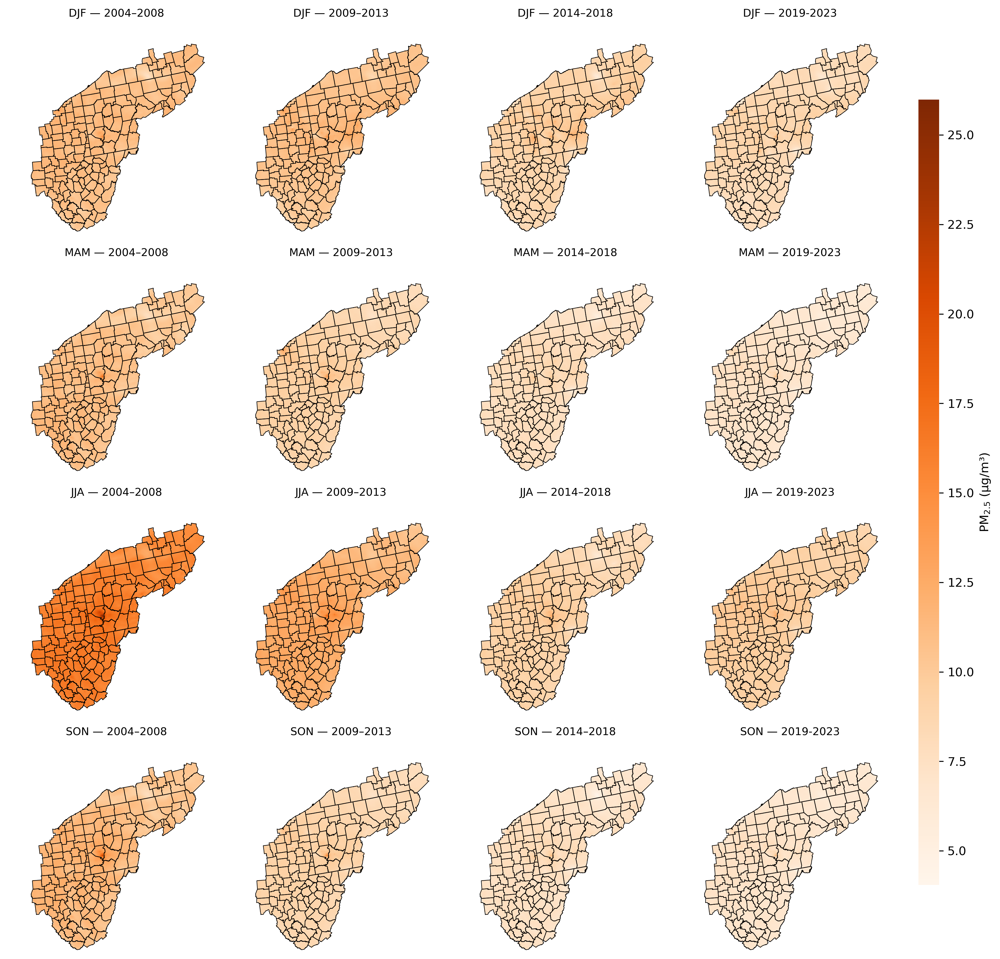

In [13]:
windows = {
    '2004–2008': (2004, 2008),
    '2009–2013':   (2009, 2013),
    '2014–2018':  (2014, 2018),
    '2019-2023':(2019, 2023)
    
}
seasons_order = ['DJF','MAM','JJA','SON']

win_means = {}
for label, (y0,y1) in windows.items():
    win_means[label] = seasonal_by_year.sel(year=slice(y0,y1)).mean('year')  # dims: season,y,x

stack_for_scale = xr.concat([win_means[k]['pm25'] for k in win_means], dim='season')
vmin = float(stack_for_scale.min())
vmax = float(stack_for_scale.max())

fig = plt.figure(figsize=(12, 12), dpi=300)
gs = gridspec.GridSpec(nrows=4, ncols=4, figure=fig, wspace=0.04, hspace=0.08)
for r, s in enumerate(seasons_order):
    for c, label in enumerate(windows.keys()):
        ax = fig.add_subplot(gs[r, c])
        im = win_means[label]['pm25'].sel(season=s).plot(
            ax=ax, x='Projected X', y='Projected Y',
            cmap='Oranges', vmin=vmin, vmax=vmax, add_colorbar=False
        )
        study_area.plot(ax=ax, facecolor='none', edgecolor='k', linewidth=0.5)
        ax.set_title(f'{s} — {label}', fontsize=9)
        ax.axis('off')

cax = fig.add_axes([0.92, 0.12, 0.02, 0.76])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'PM$_{2.5}$ (µg/m³)')
cbar.outline.set_visible(False)
plt.subplots_adjust(left=0.04, right=0.9, top=0.96, bottom=0.05)
plt.show()

# Daily maps

Selected dates by window:
 2004–2008 — Low (5th)    : 2007-02-23
 2004–2008 — Median (50th): 2004-06-13
 2004–2008 — High (95th)  : 2004-02-19
 2009–2013 — Low (5th)    : 2009-11-12
 2009–2013 — Median (50th): 2012-11-08
 2009–2013 — High (95th)  : 2009-06-08
 2014–2018 — Low (5th)    : 2014-10-19
 2014–2018 — Median (50th): 2015-01-27
 2014–2018 — High (95th)  : 2018-07-14
 2019-2023 — Low (5th)    : 2022-10-08
 2019-2023 — Median (50th): 2020-07-15
 2019-2023 — High (95th)  : 2019-03-02


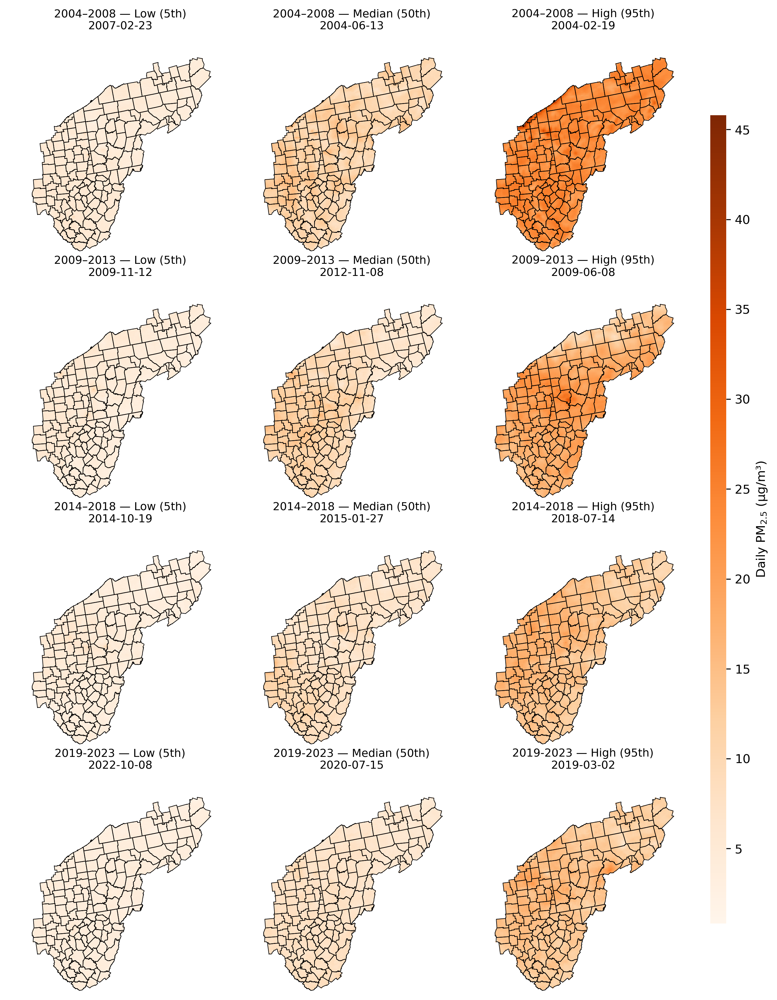

In [19]:
series = ds_daily['pm25'].mean(('y','x'), skipna=True).to_series()

def pick_three(s: pd.Series):
    q = s.quantile([0.05, 0.50, 0.95]).to_dict()
    return [
        ('Low (5th)',     (s - q[0.05]).abs().idxmin()),
        ('Median (50th)', (s - q[0.50]).abs().idxmin()),
        ('High (95th)',   (s - q[0.95]).abs().idxmin()),
    ]

window_picks = {}
for label, (y0, y1) in windows.items():
    sub = series.loc[f'{y0}-01-01': f'{y1}-12-31']
    if len(sub) == 0: 
        continue
    window_picks[label] = pick_three(sub)

print("Selected dates by window:")
for label, triples in window_picks.items():
    for tlabel, dt in triples:
        print(f"{label:>10} — {tlabel:<13}: {pd.Timestamp(dt).date()}")

all_times = [dt for triples in window_picks.values() for _, dt in triples]
subset = ds_daily.sel(time=sorted(all_times))
vmin = float(subset['pm25'].min())
vmax = float(subset['pm25'].max())

fig = plt.figure(figsize=(9, 12), dpi=300)
gs = gridspec.GridSpec(nrows=4, ncols=3, figure=fig, wspace=0.04, hspace=0.08)
col_labels = ['Low (5th)', 'Median (50th)', 'High (95th)']
row_labels = list(windows.keys())

for r, win_label in enumerate(row_labels):
    triples = dict(window_picks[win_label])
    for c, clabel in enumerate(col_labels):
        t = triples[clabel]
        ax = fig.add_subplot(gs[r, c])
        im = ds_daily['pm25'].sel(time=t).plot(
            ax=ax, x='Projected X', y='Projected Y',
            cmap='Oranges', vmin=vmin, vmax=vmax, add_colorbar=False
        )
        
        try:
            study_area.plot(ax=ax, facecolor='none', edgecolor='k', linewidth=0.5)
        except NameError:
            pass
        ax.set_title(f"{win_label} — {clabel}\n{pd.Timestamp(t).date()}", fontsize=9)
        ax.axis('off')

cax = fig.add_axes([0.92, 0.12, 0.02, 0.76])
cbar = plt.colorbar(im, cax=cax)
cbar.set_label(r'Daily PM$_{2.5}$ (µg/m³)')
cbar.outline.set_visible(False)

plt.subplots_adjust(left=0.04, right=0.9, top=0.96, bottom=0.05)
plt.show()

Chosen same-day-per-season dates:
 2004–2008 — DJF: 2006-02-15
 2004–2008 — MAM: 2006-05-15
 2004–2008 — JJA: 2006-08-15
 2004–2008 — SON: 2006-11-15
 2009–2013 — DJF: 2011-02-15
 2009–2013 — MAM: 2011-05-15
 2009–2013 — JJA: 2011-08-15
 2009–2013 — SON: 2011-11-15
 2014–2018 — DJF: 2016-02-15
 2014–2018 — MAM: 2016-05-15
 2014–2018 — JJA: 2016-08-15
 2014–2018 — SON: 2016-11-15
 2019-2023 — DJF: 2021-02-15
 2019-2023 — MAM: 2021-05-15
 2019-2023 — JJA: 2021-08-15
 2019-2023 — SON: 2021-11-15


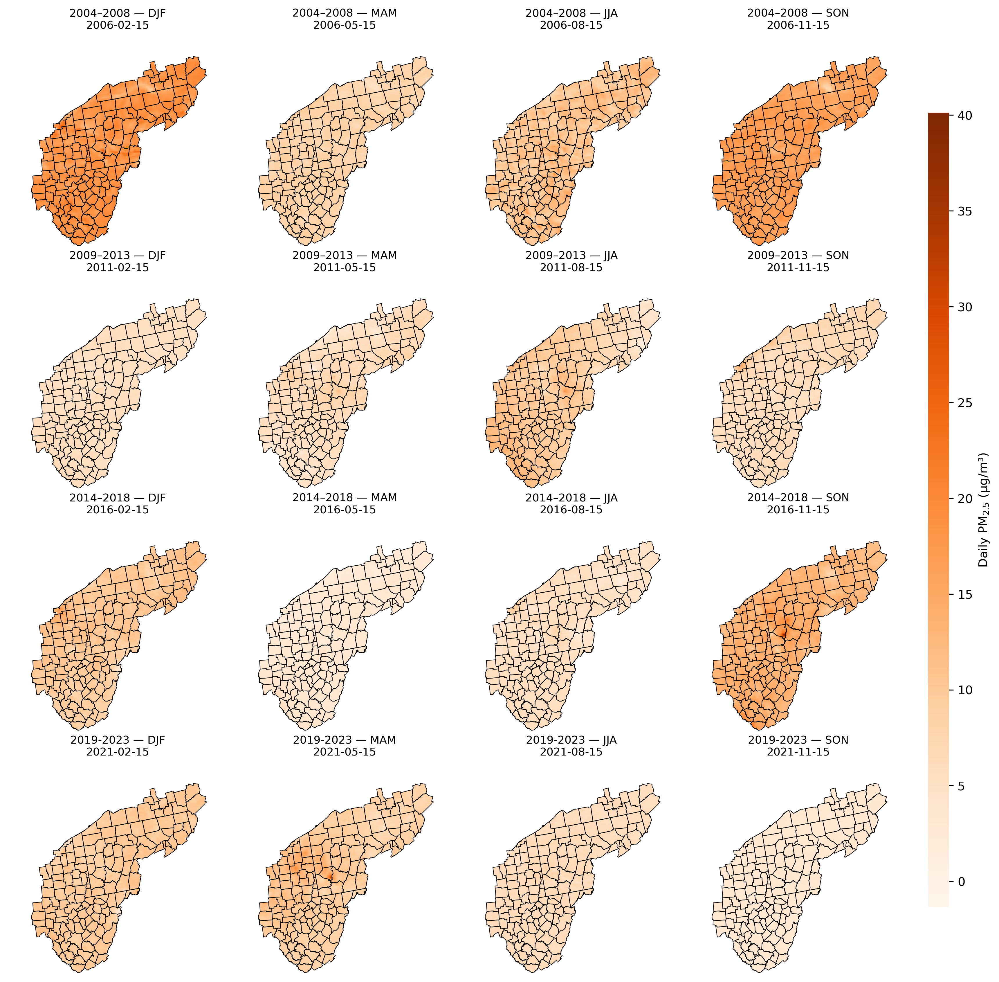

In [21]:
season_anchor_md = {
    'DJF': (2, 15),   # Feb 15
    'MAM': (5, 15),   # May 15
    'JJA': (8, 15),   # Aug 15
    'SON': (11, 15),  # Nov 15
}
seasons_order = ['DJF','MAM','JJA','SON']

times = pd.to_datetime(ds_daily['time'].values)
season_series = pd.Series([season_of_month(t.month) for t in times], index=times)

def nearest_same_day_in_window(season, y0, y1, month, day, primary_pad=7, fallback_pad=15):

    midyear = int(round((y0 + y1) / 2))
    target = pd.Timestamp(midyear, month, day)

    mask_win = (times >= pd.Timestamp(f'{y0}-01-01')) & (times <= pd.Timestamp(f'{y1}-12-31'))
    mask_season = (season_series == season)
    candidates = times[mask_win & mask_season]

    if len(candidates) == 0:
        return None

    delta = np.abs((candidates - target).to_numpy())

    near = candidates[delta <= pd.Timedelta(days=primary_pad)]
    if len(near) > 0:
        return near[np.argmin(np.abs((near - target).to_numpy()))]

    near = candidates[np.abs((candidates - target).to_numpy()) <= pd.Timedelta(days=fallback_pad)]
    if len(near) > 0:
        return near[np.argmin(np.abs((near - target).to_numpy()))]

    return candidates[np.argmin(delta)]


picked = {}  # {(window_label, season): timestamp}
for wlabel, (y0, y1) in windows.items():
    for s in seasons_order:
        m, d = season_anchor_md[s]
        dt = nearest_same_day_in_window(s, y0, y1, m, d)
        if dt is not None:
            picked[(wlabel, s)] = dt

print("Chosen same-day-per-season dates:")
for wlabel in windows.keys():
    for s in seasons_order:
        dt = picked.get((wlabel, s), None)
        print(f"{wlabel:>10} — {s}: {pd.Timestamp(dt).date() if dt is not None else 'N/A'}")


sel_times = sorted({dt for dt in picked.values() if dt is not None})
subset = ds_daily.sel(time=sel_times)
vmin = float(subset['pm25'].min())
vmax = float(subset['pm25'].max())


fig = plt.figure(figsize=(12, 12), dpi=300)
gs = gridspec.GridSpec(nrows=4, ncols=4, figure=fig, wspace=0.04, hspace=0.08)

row_labels = list(windows.keys())
for r, wlabel in enumerate(row_labels):
    for c, s in enumerate(seasons_order):
        ax = fig.add_subplot(gs[r, c])
        dt = picked.get((wlabel, s), None)
        if dt is not None:
            im = ds_daily['pm25'].sel(time=dt).plot(
                ax=ax, x='Projected X', y='Projected Y',
                cmap='Oranges', vmin=vmin, vmax=vmax, add_colorbar=False
            )
            try:
                study_area.plot(ax=ax, facecolor='none', edgecolor='k', linewidth=0.5)
            except NameError:
                pass
            ax.set_title(f"{wlabel} — {s}\n{pd.Timestamp(dt).date()}", fontsize=9)
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', fontsize=10)
        ax.axis('off')


cax = fig.add_axes([0.92, 0.12, 0.02, 0.76])
cbar = plt.colorbar(im, cax=cax)
cbar.set_label(r'Daily PM$_{2.5}$ (µg/m³)')
cbar.outline.set_visible(False)

plt.subplots_adjust(left=0.04, right=0.9, top=0.96, bottom=0.05)
plt.show()